In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import cv2
import sys
import torch
import time
from scipy.ndimage import gaussian_filter

In [2]:
#from fastsam import FastSAM
from ultralytics import FastSAM
model = FastSAM('FastSAM.pt') # FastSAM.pt or FastSAM-s.pt(smaller & less accurate)

def genfs_numpy(image):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    eres = model(image, device=device, retina_masks=True, imgsz=1024, conf=0.4, iou=0.9,)
    masks_cpu = eres[0].masks.data.cpu().detach().numpy()
    xyxy = eres[0].boxes.xyxy.cpu().detach().numpy().astype(int)

    ret = []
    for i in range(0, len(masks_cpu)):
        ret.append({
            'segmentation': masks_cpu[i],
            'bbox': [xyxy[i][0], xyxy[i][1], xyxy[i][2]-xyxy[i][0], xyxy[i][3]-xyxy[i][1]],
            'xyxy': xyxy[i],
            'area': np.count_nonzero(masks_cpu[i] == 1), # torch.sum(masks_cpu[i] == 1) when using tensors
        })

    return sorted(ret, key=(lambda x: x['area']), reverse=True)

In [3]:
# Image plotting utils

def show_anns(anns):
    if len(anns) == 0:
        return
    ax = plt.gca()
    #ax.set_autoscale_on(False)

    img = np.ones((anns[0]['segmentation'].shape[0], anns[0]['segmentation'].shape[1], 4))
    img[:,:,3] = 0
    for ann in anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.35]])
        img[m==1] = color_mask
    ax.imshow(img)

def draw_rectangle(anns, color='r', linewidth=2):
    ax = plt.gca()
    for ann in anns:
        x, y, w, h = ann['bbox']
        rect = patches.Rectangle((x, y), w, h, linewidth=linewidth, edgecolor=color, facecolor='none')
        ax.add_patch(rect)

In [4]:
# Process output from sam utils

# Filter out the masks to get the list of potential page(s)
# Return of a list of masks that are potential pages
# Consider the masks whose area > apct * frame_size
# Accept a mask that has < X (area * fpct) number of False inside the bbox
def get_pages(masks, apct, fpct):
    p = []
    if len(masks) == 0:
        return p

    frame_size = masks[0]['segmentation'].size
    for m in masks:
        if m['area'] > frame_size * apct:
            bbox = m['bbox']
            num_falses = np.count_nonzero(m['segmentation'][bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]] == False)
            if num_falses < m['area'] * fpct:
                p.append(m)
    return p

# If two pages are in a frame, then there maybe 3 segments
# 1. covering both pages
# 2. page 1
# 3. page 2
# Filter out the page #1, since the bbox is covered by #2 + #3
def filter_covered_pages(pages, tpct):
    filtered = []
    if len(pages) == 0:
        return filtered
    elif len(pages) == 2:
        return pages


    img_mask = np.full(pages[0]['segmentation'].shape, False)

    for p in sorted(pages, key=(lambda x: x['area'])):
        bbox = p['bbox']
        num_trues = np.count_nonzero(img_mask[bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]] == True)
        if num_trues < p['area'] * tpct:
            filtered.append(p)
        img_mask[p['segmentation'] == 1] = True
    return filtered

def find_pages_nb(masks, apct, amx, fpct):
    p = []
    if len(masks) == 0:
        return p

    frame_size = masks[0]['segmentation'].size
    for m in masks:
        if m['area'] > frame_size * apct and m['area'] < frame_size * amx:
            bbox = m['bbox']
            num_falses = np.count_nonzero(m['segmentation'][bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]] == False)
            if num_falses < m['area'] * fpct:
                p.append(m)
    return p

In [39]:
imgp = 'trash/frames/00104.jpg'
masks = genfs_numpy(imgp)


image 1/1 /home/neel/flipatron/trash/frames/00104.jpg: 1024x576 12 objects, 58.7ms
Speed: 3.1ms preprocess, 58.7ms inference, 5.2ms postprocess per image at shape (1, 3, 1024, 576)


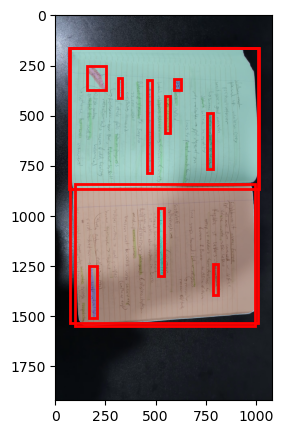

In [40]:
plt.figure(figsize=(5,5))
plt.imshow(cv2.imread(imgp))
#plt.axis('off')
show_anns(masks)
draw_rectangle(masks, color='r', linewidth=2)
plt.show()

2


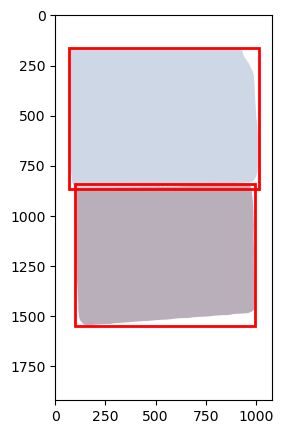

In [48]:
#pgs = filter_covered_pages(get_pages(masks, 0.20, 0.10), 0.20)
pgs = find_pages_nb(masks, 0.20, 0.50, 0.20)
print(len(pgs))
plt.figure(figsize=(5,5))
#plt.imshow(cv2.imread(imgp))
#plt.axis('off')
show_anns(pgs)
draw_rectangle(pgs, color='r', linewidth=2)
plt.show()

In [8]:
# Test on full notebook

fin_pg = []
st = time.time()
dire = 'trash/frames/'
for i in range(0, 112):
    il = str(i) + '.jpg'
    while len(il) != 9:
        il = "0" + il
    fn = dire+il

    masks = genfs_numpy(fn)

    pgs = find_pages_nb(masks, 0.20, 0.50, 0.20)
    fin_pg.append(pgs)
print('\nTotal Time:', time.time()-st)


image 1/1 /home/neel/flipatron/trash/frames/00000.jpg: 1024x576 10 objects, 56.6ms
Speed: 3.0ms preprocess, 56.6ms inference, 4.7ms postprocess per image at shape (1, 3, 1024, 576)

image 1/1 /home/neel/flipatron/trash/frames/00001.jpg: 1024x576 8 objects, 56.5ms
Speed: 2.8ms preprocess, 56.5ms inference, 4.1ms postprocess per image at shape (1, 3, 1024, 576)

image 1/1 /home/neel/flipatron/trash/frames/00002.jpg: 1024x576 9 objects, 51.4ms
Speed: 2.8ms preprocess, 51.4ms inference, 4.3ms postprocess per image at shape (1, 3, 1024, 576)

image 1/1 /home/neel/flipatron/trash/frames/00003.jpg: 1024x576 7 objects, 51.1ms
Speed: 3.1ms preprocess, 51.1ms inference, 3.6ms postprocess per image at shape (1, 3, 1024, 576)

image 1/1 /home/neel/flipatron/trash/frames/00004.jpg: 1024x576 8 objects, 54.0ms
Speed: 3.0ms preprocess, 54.0ms inference, 4.0ms postprocess per image at shape (1, 3, 1024, 576)

image 1/1 /home/neel/flipatron/trash/frames/00005.jpg: 1024x576 8 objects, 51.6ms
Speed: 3.0m

In [16]:
# Find if the pages are mono increasing then mono decreasing
# slope over range is (slope) <-- filter for noise from sam

# OPTMIZE W NUMPY FUNCS
def mono(mask, rnge, slope):
    frs = mask['segmentation']
    #frs = gaussian_filter(frs, sigma=10)
    for n4 in range(0, 4):
        ft = []
        for i in frs:
            first1 = np.argmax(i)
            first1 = first1 if i[first1] != 0 else len(i)
            ft.append(first1)
    
        fi = False
        for i in range(0, len(ft)-rnge):
            if abs(ft[i] - ft[i+rnge])/rnge > slope:
                if ft[i+rnge] > ft[i]:
                    fi = True
                elif fi:
                    return False
        frs = np.rot90(frs)
    
    return True

In [19]:
goodpg = []
for i in fin_pg:
    g = (len(i) == 2)
    for j in i:
        g = (g and mono(j, 10, 0.50))
#        g = (g and mono(j, 2, 10))
    goodpg.append(g)

In [18]:
for i in range(0,len(goodpg)):
    print(i, goodpg[i])

0 True
1 False
2 False
3 False
4 False
5 False
6 False
7 False
8 False
9 False
10 False
11 False
12 False
13 False
14 False
15 False
16 False
17 False
18 False
19 False
20 False
21 False
22 False
23 False
24 False
25 False
26 False
27 False
28 False
29 False
30 False
31 False
32 False
33 False
34 False
35 False
36 False
37 False
38 True
39 True
40 False
41 False
42 False
43 False
44 False
45 False
46 False
47 False
48 False
49 False
50 False
51 False
52 False
53 False
54 False
55 False
56 False
57 False
58 False
59 False
60 False
61 False
62 False
63 True
64 False
65 False
66 False
67 False
68 False
69 False
70 False
71 False
72 False
73 False
74 False
75 False
76 False
77 False
78 False
79 False
80 False
81 False
82 False
83 False
84 False
85 False
86 False
87 False
88 False
89 False
90 False
91 False
92 False
93 False
94 False
95 False
96 False
97 True
98 False
99 False
100 False
101 False
102 True
103 False
104 False
105 False
106 False
107 False
108 False
109 False
110 False
111 Tr